In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [3]:
# Назви стовпців датасету
columns = [
    'age', 'sex', 'cp', 'trestbps', 'chol',
    'fbs', 'restecg', 'thalach', 'exang',
    'oldpeak', 'slope', 'ca', 'thal', 'num'
]

# Завантаження даних
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data"

df = pd.read_csv(url, names=columns)

# Перегляд перших записів
print(df.head())

# Інформація про датасет
print(df.info())
print("Розмір датасету:", df.shape)

    age  sex   cp  trestbps   chol  fbs  restecg  thalach  exang  oldpeak  \
0  63.0  1.0  1.0     145.0  233.0  1.0      2.0    150.0    0.0      2.3   
1  67.0  1.0  4.0     160.0  286.0  0.0      2.0    108.0    1.0      1.5   
2  67.0  1.0  4.0     120.0  229.0  0.0      2.0    129.0    1.0      2.6   
3  37.0  1.0  3.0     130.0  250.0  0.0      0.0    187.0    0.0      3.5   
4  41.0  0.0  2.0     130.0  204.0  0.0      2.0    172.0    0.0      1.4   

   slope   ca thal  num  
0    3.0  0.0  6.0    0  
1    2.0  3.0  3.0    2  
2    2.0  2.0  7.0    1  
3    3.0  0.0  3.0    0  
4    1.0  0.0  3.0    0  
<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    float64
 2   cp        303 non-null    float64
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs      

In [5]:
df = df.apply(pd.to_numeric, errors='coerce')

print("Пропущені значення:")
print(df.isnull().sum())

# Видалення рядків із пропущеними значеннями
df = df.dropna()

print("Розмір після очищення:", df.shape)

Пропущені значення:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
num         0
dtype: int64
Розмір після очищення: (297, 14)


In [7]:
df['risk'] = (df['num']>0).astype(int)
df = df.drop(columns=['num'])
print(df.head())

    age  sex   cp  trestbps   chol  fbs  restecg  thalach  exang  oldpeak  \
0  63.0  1.0  1.0     145.0  233.0  1.0      2.0    150.0    0.0      2.3   
1  67.0  1.0  4.0     160.0  286.0  0.0      2.0    108.0    1.0      1.5   
2  67.0  1.0  4.0     120.0  229.0  0.0      2.0    129.0    1.0      2.6   
3  37.0  1.0  3.0     130.0  250.0  0.0      0.0    187.0    0.0      3.5   
4  41.0  0.0  2.0     130.0  204.0  0.0      2.0    172.0    0.0      1.4   

   slope   ca  thal  risk  
0    3.0  0.0   6.0     0  
1    2.0  3.0   3.0     1  
2    2.0  2.0   7.0     1  
3    3.0  0.0   3.0     0  
4    1.0  0.0   3.0     0  


In [8]:
print(df['risk'].value_counts())

risk
0    160
1    137
Name: count, dtype: int64


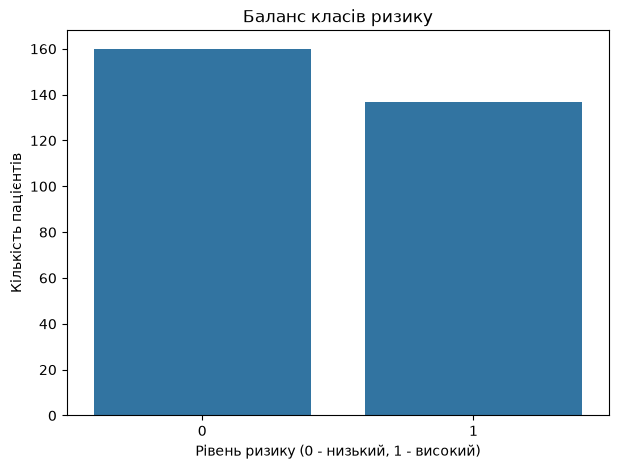

In [11]:
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x='risk')

plt.title('Баланс класів ризику')
plt.xlabel('Рівень ризику (0 - низький, 1 - високий)')
plt.ylabel('Кількість пацієнтів')

plt.show()


In [12]:
# Відокремлення ознак та цільової змінної
X = df.drop(columns=['risk'])
y = df['risk']

# Розділення даних
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Перевірка розмірів
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (237, 13)
X_test: (60, 13)
y_train: (237,)
y_test: (60,)
